Необходимые импорты

In [18]:
%pip install colorednoise

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import colorednoise as cn
import warnings

from pathlib import Path


# ПОЛУЧЕНИЕ, ПОДГОТОВКА И СИНХРОНИЗАЦИЯ ДАННЫХ

In [20]:
DATA_DIR = Path(r"C:\Users\mrtim\InformaticsLab\informatics_laba_2025_Orosv2\Informatics_2026\Signal processing\measurements")

SENSORS = [
    "Gyroscope", #Готовые показатели угловой скорости
    "GyroscopeUncalibrated", #Сырые показатели того же
    "Gravity", # Вектор гравитации
    "TotalAcceleration", # величина общего ускорения
    "AccelerometerUncalibrated", # сырое ускорение без компенсации смещения
    "Accelerometer", # Готовое полное ускорение
]

# компенсация смещения - компенсация систематической ошибки нуля (устройства)

AXES = ["x", "y", "z"]

# Синхронизированная частота дискретизации.
# None = automatically determine from the data.
TARGET_FREQUENCY = None

# Загрузка 

streams = {}

for sensor in SENSORS:
    path = DATA_DIR / f"{sensor}.csv"

    df = pd.read_csv(path)

    # Сортировка измерений по времени.
    df = df.sort_values("time").reset_index(drop=True)

    df[AXES] = df[AXES].apply(pd.to_numeric)

    streams[sensor] = df

print("DATA LOADED")
print("=" * 60)

for name, df in streams.items():
    print(f"{name}: {len(df)} measurements")

DATA LOADED
Gyroscope: 7709 measurements
GyroscopeUncalibrated: 7709 measurements
Gravity: 7711 measurements
TotalAcceleration: 7707 measurements
AccelerometerUncalibrated: 7708 measurements
Accelerometer: 7712 measurements


Проверка данных

In [21]:
print("\nDATA STATISTICS")
print("=" * 60)

for name, df in streams.items():

    # Интервалы между измерениями.
    dt = df["seconds_elapsed"].diff().dropna()

    median_dt = dt.median()
    frequency = 1 / median_dt if median_dt > 0 else np.nan

    print(f"\n{name}")
    print(f"  Samples: {len(df)}")
    print(f"  Duration: {df['seconds_elapsed'].iloc[-1] - df['seconds_elapsed'].iloc[0]:.3f} s")
    print(f"  Start: {df['seconds_elapsed'].iloc[0]:.3f} s")
    print(f"  End: {df['seconds_elapsed'].iloc[-1]:.3f} s")
    print(f"  Median interval: {median_dt * 1000:.3f} ms")
    print(f"  Sampling frequency: {frequency:.2f} Hz")
    print(f"  Missing values:\n{df.isnull().sum().to_dict()}")
    print(f"  Duplicate timestamps: {df['time'].duplicated().sum()}")


DATA STATISTICS

Gyroscope
  Samples: 7709
  Duration: 75.939 s
  Start: 0.298 s
  End: 76.237 s
  Median interval: 9.852 ms
  Sampling frequency: 101.50 Hz
  Missing values:
{'time': 0, 'seconds_elapsed': 0, 'z': 0, 'y': 0, 'x': 0}
  Duplicate timestamps: 0

GyroscopeUncalibrated
  Samples: 7709
  Duration: 75.939 s
  Start: 0.298 s
  End: 76.237 s
  Median interval: 9.852 ms
  Sampling frequency: 101.50 Hz
  Missing values:
{'time': 0, 'seconds_elapsed': 0, 'z': 0, 'y': 0, 'x': 0}
  Duplicate timestamps: 0

Gravity
  Samples: 7711
  Duration: 75.958 s
  Start: 0.283 s
  End: 76.242 s
  Median interval: 9.852 ms
  Sampling frequency: 101.50 Hz
  Missing values:
{'time': 0, 'seconds_elapsed': 0, 'z': 0, 'y': 0, 'x': 0}
  Duplicate timestamps: 0

TotalAcceleration
  Samples: 7707
  Duration: 75.919 s
  Start: 0.323 s
  End: 76.242 s
  Median interval: 9.852 ms
  Sampling frequency: 101.50 Hz
  Missing values:
{'time': 0, 'seconds_elapsed': 0, 'z': 0, 'y': 0, 'x': 0}
  Duplicate timesta

Визуализация

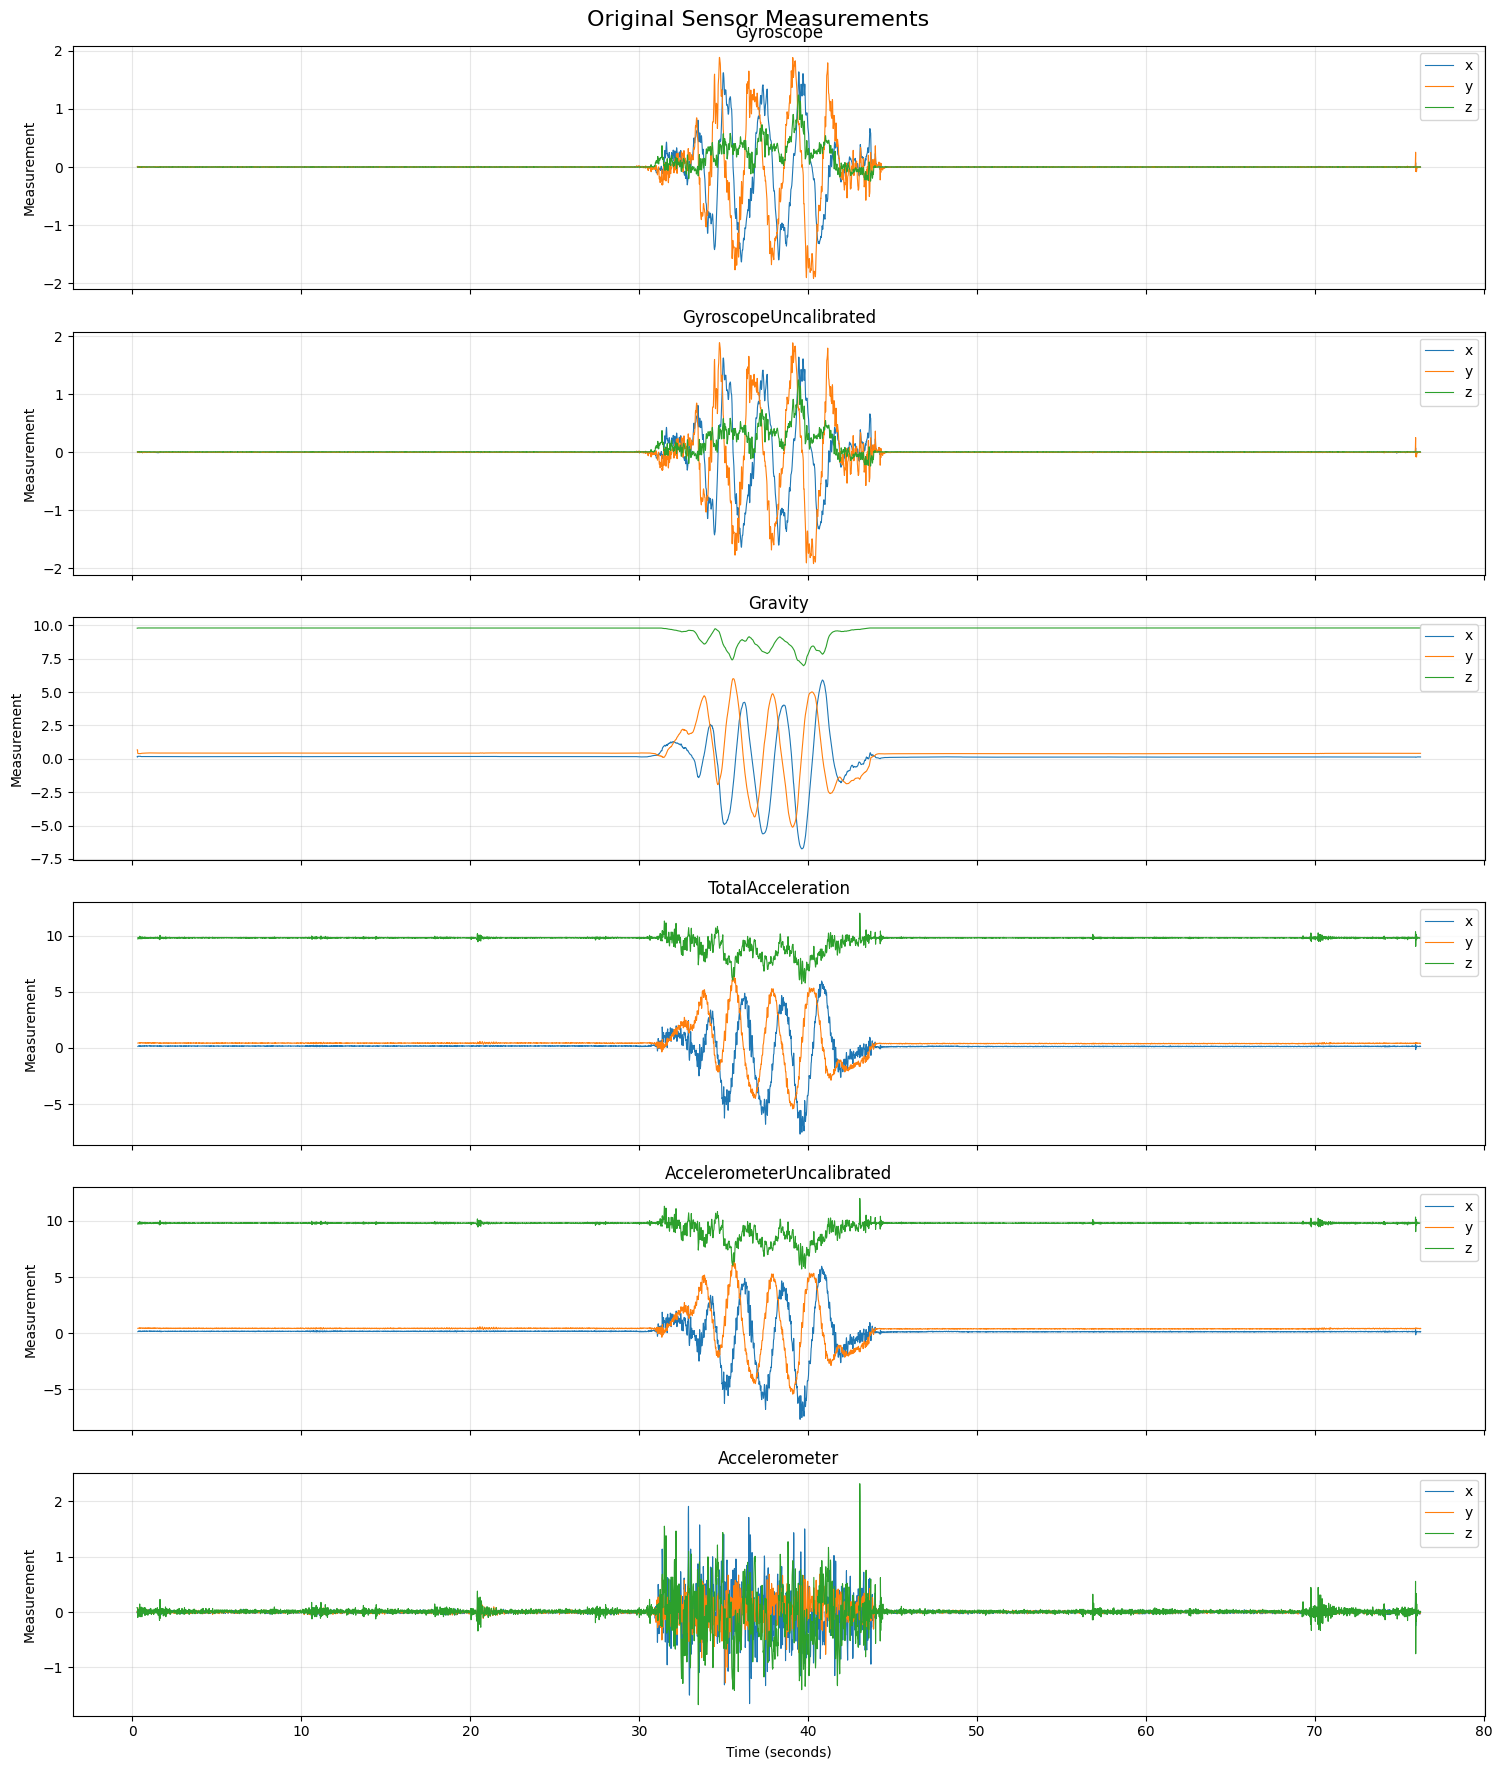

In [22]:
fig, axes = plt.subplots(
    nrows=6,
    ncols=1,
    figsize=(15, 18),
    sharex=True
)

for ax, (name, df) in zip(axes, streams.items()):

    for axis in AXES:
        ax.plot(
            df["seconds_elapsed"],
            df[axis],
            label=axis,
            linewidth=0.8
        )

    ax.set_title(name)
    ax.set_ylabel("Measurement")
    ax.grid(True, alpha=0.3)
    ax.legend(loc="upper right")

axes[-1].set_xlabel("Time (seconds)")

plt.suptitle("Original Sensor Measurements", fontsize=16)
plt.tight_layout()
plt.show()

Определение общего временного потока

In [23]:
start_time = max(
    df["seconds_elapsed"].iloc[0]
    for df in streams.values()
)

end_time = min(
    df["seconds_elapsed"].iloc[-1]
    for df in streams.values()
)

# Определение целевой частоты синхронизации.
if TARGET_FREQUENCY is None:

    median_intervals = [
        df["seconds_elapsed"].diff().median()
        for df in streams.values()
    ]

    target_dt = np.median(median_intervals)

else:
    target_dt = 1.0 / TARGET_FREQUENCY

target_frequency = 1.0 / target_dt

print("\nSYNCHRONIZATION SETTINGS")
print("=" * 60)
print(f"Common start: {start_time:.6f} s")
print(f"Common end: {end_time:.6f} s")
print(f"Target interval: {target_dt * 1000:.3f} ms")
print(f"Target frequency: {target_frequency:.2f} Hz")



SYNCHRONIZATION SETTINGS
Common start: 0.322596 s
Common end: 76.236648 s
Target interval: 9.852 ms
Target frequency: 101.50 Hz


Синхронизация потоков и их визуализация

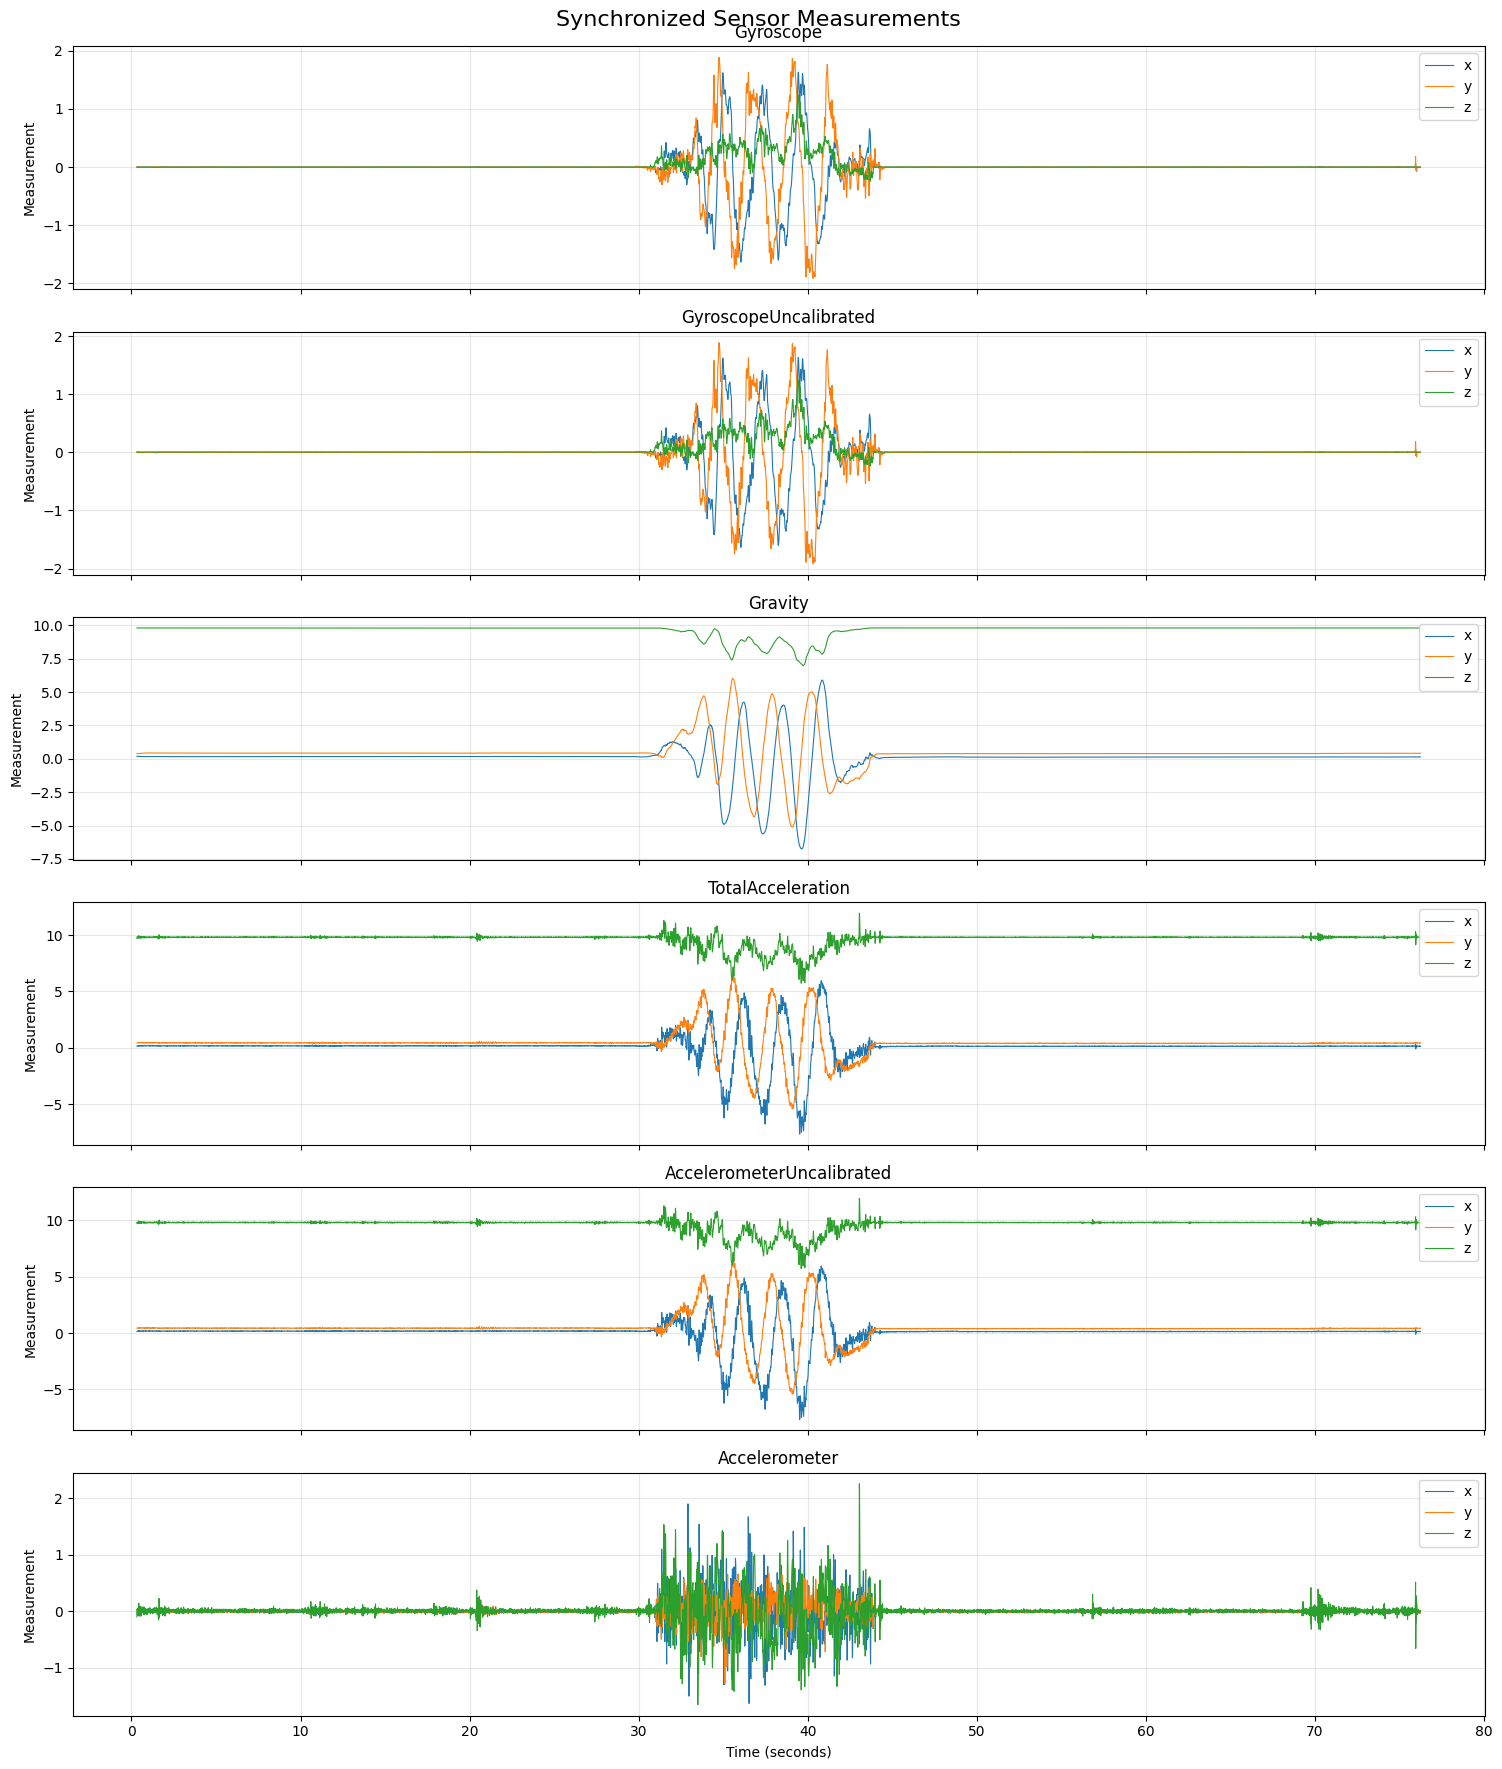

In [24]:
# Создаём общий временной трек.
common_time = np.arange(
    start_time,
    end_time,
    target_dt
)

synchronized = pd.DataFrame({
    "seconds_elapsed": common_time
})

for name, df in streams.items():

    # Забираем нужные 
    source = df[["seconds_elapsed"] + AXES].copy()

    # Удаление дупликатов для строгого возрастания.
    source = source.drop_duplicates(
        subset="seconds_elapsed",
        keep="first"
    )

    # Кусочно-линейная интерполяция.
    for axis in AXES:

        values = np.interp(
            common_time,
            source["seconds_elapsed"],
            source[axis]
        )

        synchronized[f"{name}_{axis}"] = values

fig, axes = plt.subplots(
    nrows=6,
    ncols=1,
    figsize=(15, 18),
    sharex=True
)

for ax, name in zip(axes, SENSORS):

    for axis in AXES:
        column = f"{name}_{axis}"

        ax.plot(
            synchronized["seconds_elapsed"],
            synchronized[column],
            label=axis,
            linewidth=0.8
        )

    ax.set_title(name)
    ax.set_ylabel("Measurement")
    ax.grid(True, alpha=0.3)
    ax.legend(loc="upper right")

axes[-1].set_xlabel("Time (seconds)")

plt.suptitle("Synchronized Sensor Measurements", fontsize=16)
plt.tight_layout()
plt.show()


Сохранение результатов

In [25]:
# Сохраняем абсолютные временные метки, не переводя большие int64 в float.
OUTPUT_DIR = Path("output")
OUTPUT_DIR.mkdir(exist_ok=True)

gyro_first = streams["Gyroscope"].iloc[0]
first_time_ns = int(gyro_first["time"])
first_elapsed = float(gyro_first["seconds_elapsed"])
synchronized.insert(
    0,
    "time",
    first_time_ns + np.rint(
        (synchronized["seconds_elapsed"].to_numpy() - first_elapsed) * 1e9
    ).astype(np.int64),
)

synchronized.to_csv(OUTPUT_DIR / "synchronized_measurements.csv", index=False)
print(f"Синхронизированные данные сохранены: {OUTPUT_DIR / 'synchronized_measurements.csv'}")
print(f"Количество синхронизированных измерений: {len(synchronized)}")

Синхронизированные данные сохранены: output\synchronized_measurements.csv
Количество синхронизированных измерений: 7706


# РЕАЛИЗАЦИЯ ТРЁХ ШУМОВЫХ ПРОФИЛЕЙ

Формирование зашумлённых значений

АМПЛИТУДЫ ШУМА (2·СКО по неподвижному участку)
Gyroscope: X=0.00416, Y=0.00493, Z=0.00207
AccelerometerUncalibrated: X=0.02774, Y=0.03012, Z=0.09404

ЧАСТОТЫ ПРОФИЛЕЙ ШУМА ПО ОСЯМ

Gyroscope
  fs = 101.50 Гц, Nyquist = 50.75 Гц
  x: задано    10.0 Гц -> частоты шума до   10.00 Гц
  y: задано   100.0 Гц -> частоты шума до   50.75 Гц (ограничено частотой Найквиста)
  z: задано  1000.0 Гц -> частоты шума до   50.75 Гц (ограничено частотой Найквиста)

AccelerometerUncalibrated
  fs = 101.50 Гц, Nyquist = 50.75 Гц
  x: задано    10.0 Гц -> частоты шума до   10.00 Гц
  y: задано   100.0 Гц -> частоты шума до   50.75 Гц (ограничено частотой Найквиста)
  z: задано  1000.0 Гц -> частоты шума до   50.75 Гц (ограничено частотой Найквиста)


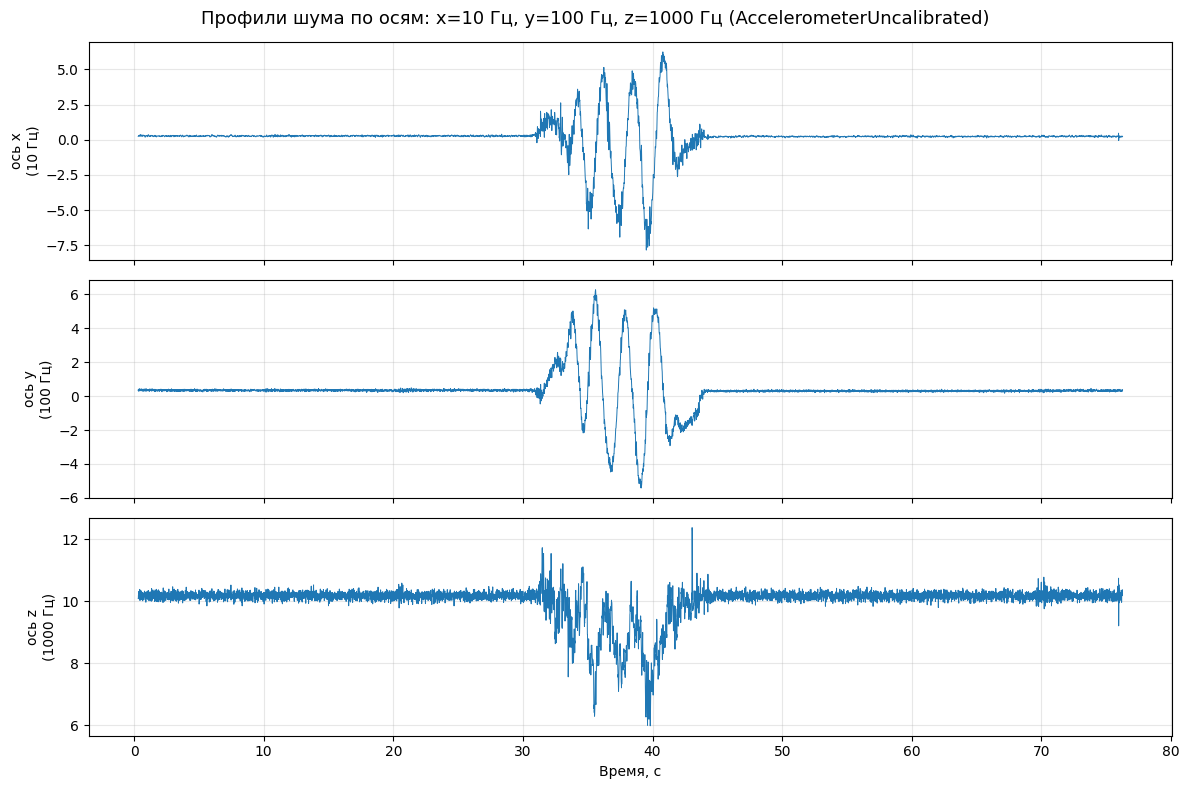

In [26]:
# ==============================================================================
# ГЕНЕРАЦИЯ ШУМОВЫХ ПРОФИЛЕЙ И ДОБАВЛЕНИЕ ПОГРЕШНОСТЕЙ
# ==============================================================================
# Для каждой координаты задаётся свой частотный профиль шума:
#     x -> 10 Гц
#     y -> 100 Гц
#     z -> 1000 Гц
#
# Амплитуда шума по каждой оси определяется как 2·СКО
# на начальном неподвижном участке.
#
# Дополнительно к случайному шуму моделируются:
#     BIAS  — постоянное смещение показаний датчика;
#     SCALE — масштабная погрешность.
#
# Если заданная частота выше частоты Найквиста, спектр шума
# ограничивается частотой Найквиста.

AXIS_FREQUENCIES = {
    "x": 10.0,
    "y": 100.0,
    "z": 1000.0
}

AXES = ("x", "y", "z")

# Количество первых отсчётов, которые считаем неподвижным участком
STATIONARY_SAMPLES = 200


# ==============================================================================
# 1. ОЦЕНКА АМПЛИТУДЫ ШУМА
# ==============================================================================

def estimate_noise_amplitudes(df, n_stationary):
    """
    Вычисляет амплитуду шума для каждой оси.

    Амплитуда принимается равной 2·СКО по первым
    n_stationary отсчётам, соответствующим неподвижному участку.
    """
    return {
        axis: float(df[axis].iloc[:n_stationary].std() * 2.0)
        for axis in AXES
    }


# Рассчитываем амплитуды отдельно для гироскопа и акселерометра
noise_amplitudes = {
    sensor: estimate_noise_amplitudes(
        streams[sensor],
        STATIONARY_SAMPLES
    )
    for sensor in ("Gyroscope", "AccelerometerUncalibrated")
}


print("=" * 60)
print("АМПЛИТУДЫ ШУМА (2·СКО по неподвижному участку)")
print("=" * 60)

for sensor, amps in noise_amplitudes.items():
    print(
        f"{sensor}: "
        f"X={amps['x']:.5f}, "
        f"Y={amps['y']:.5f}, "
        f"Z={amps['z']:.5f}"
    )


# ==============================================================================
# 2. ГЕНЕРАЦИЯ БЕЛОГО ШУМА
# ==============================================================================

def make_white_noise(n_samples, seed):
    """
    Генерирует белый шум с единичной дисперсией.

    Seed используется для того, чтобы при повторном запуске
    программы получался тот же самый шум.
    """
    rng = np.random.default_rng(seed)
    return rng.standard_normal(n_samples)


# ==============================================================================
# 3. ФОРМИРОВАНИЕ ШУМОВОГО ПРОФИЛЯ ДЛЯ ОДНОЙ ОСИ
# ==============================================================================

def build_axis_noise(n_samples, amplitude, frequency, time, base_noise):
    """
    Формирует шумовой профиль для одной оси.

    1. Берётся заранее сгенерированный белый шум base_noise.
    2. Выполняется переход в частотную область с помощью FFT.
    3. Частоты выше заданной границы удаляются.
    4. Выполняется обратное FFT.
    5. СКО полученного шума приводится к заданной amplitude.

    Если заданная частота выше частоты Найквиста,
    используется максимально доступная частота fs/2.
    """

    # Частота дискретизации исходных данных
    fs = 1.0 / np.median(np.diff(time))

    # Переход белого шума в частотную область
    spectrum = np.fft.rfft(base_noise)

    # Частоты, соответствующие коэффициентам FFT
    freqs = np.fft.rfftfreq(
        n_samples,
        d=1.0 / fs
    )

    # Реально доступная верхняя частота ограничена частотой Найквиста
    cutoff = min(frequency, fs / 2.0)

    # Убираем компоненты выше выбранной частоты
    spectrum[freqs > cutoff] = 0

    # Возвращаем сигнал во временную область
    noise = np.fft.irfft(
        spectrum,
        n=n_samples
    )

    # Масштабируем шум так, чтобы его СКО было равно
    # рассчитанной ранее амплитуде
    std = np.std(noise)

    if std > 0:
        noise = noise * (amplitude / std)

    return noise


# ==============================================================================
# 4. ПАРАМЕТРЫ СИСТЕМАТИЧЕСКИХ ПОГРЕШНОСТЕЙ
# ==============================================================================

# BIAS — постоянное смещение показаний.
# Для каждой оси и каждого датчика задаётся отдельно.
BIAS = {
    "Gyroscope": {
        "x": 0.02,
        "y": -0.015,
        "z": 0.01
    },

    "AccelerometerUncalibrated": {
        "x": 0.10,
        "y": -0.08,
        "z": 0.12
    }
}


# SCALE — относительная масштабная погрешность.
# Например SCALE = 0.02 означает увеличение показаний на 2 %.
SCALE = {
    "Gyroscope": {
        "x": 0.02,
        "y": -0.015,
        "z": 0.01
    },

    "AccelerometerUncalibrated": {
        "x": 0.03,
        "y": -0.02,
        "z": 0.025
    }
}


# ==============================================================================
# 5. ДОБАВЛЕНИЕ ПОГРЕШНОСТЕЙ К ДАННЫМ ДАТЧИКА
# ==============================================================================

def build_noisy_sensor(
    df,
    amplitudes,
    axis_freqs,
    sensor_seed,
    sensor
):
    """
    Создаёт копию данных датчика с добавленными погрешностями.

    Для каждой оси независимо добавляются:

        1. масштабная погрешность SCALE;
        2. постоянное смещение BIAS;
        3. случайный шум заданного частотного профиля.

    Итоговая модель:

        измерение =
            (1 + SCALE) * исходное значение
            + BIAS
            + шум
    """

    noisy = df.copy()

    # Временные метки
    t = noisy["seconds_elapsed"].to_numpy()

    # Количество отсчётов
    n = len(noisy)

    # Обрабатываем X, Y и Z независимо
    for i, axis in enumerate(AXES):

        # Для каждой оси используется свой seed,
        # поэтому шумы X, Y и Z различаются
        base = make_white_noise(
            n,
            seed=sensor_seed + i
        )

        # Формируем шумовой профиль данной оси
        axis_noise = build_axis_noise(
            n_samples=n,
            amplitude=amplitudes[axis],
            frequency=axis_freqs[axis],
            time=t,
            base_noise=base
        )

        # Исходные показания датчика
        original = noisy[axis].to_numpy()

        # Добавляем масштабную погрешность,
        # постоянное смещение и случайный шум
        noisy[axis] = (
            (1.0 + SCALE[sensor][axis]) * original
            + BIAS[sensor][axis]
            + axis_noise
        )

    return noisy


# ==============================================================================
# 6. СОЗДАНИЕ ЗАШУМЛЁННЫХ ДАННЫХ
# ==============================================================================

# Отдельные seed для гироскопа и акселерометра.
# Благодаря этому шум воспроизводим, но различается
# между датчиками и между осями.
SENSOR_SEEDS = {
    "Gyroscope": 1000,
    "AccelerometerUncalibrated": 2000
}


noisy_data = {
    sensor: build_noisy_sensor(
        streams[sensor],
        noise_amplitudes[sensor],
        AXIS_FREQUENCIES,
        sensor_seed=SENSOR_SEEDS[sensor],
        sensor=sensor
    )
    for sensor in (
        "Gyroscope",
        "AccelerometerUncalibrated"
    )
}


# ==============================================================================
# 7. ИНФОРМАЦИЯ О ЧАСТОТАХ ШУМОВЫХ ПРОФИЛЕЙ
# ==============================================================================

print("\n" + "=" * 60)
print("ЧАСТОТЫ ПРОФИЛЕЙ ШУМА ПО ОСЯМ")
print("=" * 60)


for sensor, df in streams.items():

    # Нас интересуют только два датчика,
    # для которых были рассчитаны шумовые параметры
    if sensor not in noise_amplitudes:
        continue

    t = df["seconds_elapsed"].to_numpy()

    # Частота дискретизации данного датчика
    fs = 1.0 / float(np.median(np.diff(t)))

    print(f"\n{sensor}")
    print(
        f"  fs = {fs:.2f} Гц, "
        f"Nyquist = {fs / 2:.2f} Гц"
    )

    for axis in AXES:

        # Частота, заданная для данной оси
        f_set = AXIS_FREQUENCIES[axis]

        # Реально доступная верхняя частота
        f_cutoff = min(
            f_set,
            fs / 2.0
        )

        if f_set > fs / 2.0:
            note = " (ограничено частотой Найквиста)"
        else:
            note = ""

        print(
            f"  {axis}: "
            f"задано {f_set:7.1f} Гц -> "
            f"частоты шума до {f_cutoff:7.2f} Гц"
            f"{note}"
        )


# ==============================================================================
# 8. ВИЗУАЛИЗАЦИЯ ЗАШУМЛЁННЫХ ДАННЫХ
# ==============================================================================

fig, axes = plt.subplots(
    3,
    1,
    figsize=(12, 8),
    sharex=True
)

fig.suptitle(
    "Профили шума по осям: "
    "x=10 Гц, y=100 Гц, z=1000 Гц "
    "(AccelerometerUncalibrated)",
    fontsize=13
)


for ax, axis in zip(axes, AXES):

    ax.plot(
        noisy_data["AccelerometerUncalibrated"]["seconds_elapsed"],
        noisy_data["AccelerometerUncalibrated"][axis],
        linewidth=0.7
    )

    ax.set_ylabel(
        f"ось {axis}\n"
        f"({AXIS_FREQUENCIES[axis]:.0f} Гц)"
    )

    ax.grid(
        True,
        alpha=0.3
    )


axes[-1].set_xlabel("Время, с")

plt.tight_layout()
plt.show()


# ==============================================================================
# 9. ФУНКЦИИ ДЛЯ СИНХРОНИЗАЦИИ
# ==============================================================================

def sync_sensor_to_common_time(
    df,
    common_time,
    axes=AXES,
    time_col="seconds_elapsed"
):
    """
    Пересемплирует данные одного датчика на общий временной трек
    common_time с помощью линейной интерполяции.

    Возвращает DataFrame:
        seconds_elapsed, x, y, z

    Исходный DataFrame не изменяется.
    """

    src = (
        df
        .drop_duplicates(
            subset=time_col,
            keep="first"
        )
        .sort_values(time_col)
    )

    out = pd.DataFrame({
        time_col: common_time
    })

    for axis in axes:
        out[axis] = np.interp(
            common_time,
            src[time_col].to_numpy(),
            src[axis].to_numpy()
        )

    return out


def extract_sensor_from_synchronized(
    sync_df,
    sensor,
    axes=AXES,
    time_col="seconds_elapsed"
):
    """
    Из общего синхронизированного DataFrame извлекает данные
    одного датчика.

    Возвращает DataFrame:
        seconds_elapsed, x, y, z
    """

    out = pd.DataFrame({
        time_col: sync_df[time_col].to_numpy()
    })

    for axis in axes:
        out[axis] = sync_df[
            f"{sensor}_{axis}"
        ].to_numpy()

    return out

ФИльтр калмана

ДИСПЕРСИИ ИЗМЕРЕНИЯ r (по неподвижному участку)
AccelerometerUncalibrated: {'x': 0.00019236563423553706, 'y': 0.00022673309234730373, 'z': 0.0022108456639105926}
Gyroscope:                 {'x': 4.325314824356726e-06, 'y': 6.064619025827754e-06, 'z': 1.0763636778766105e-06}


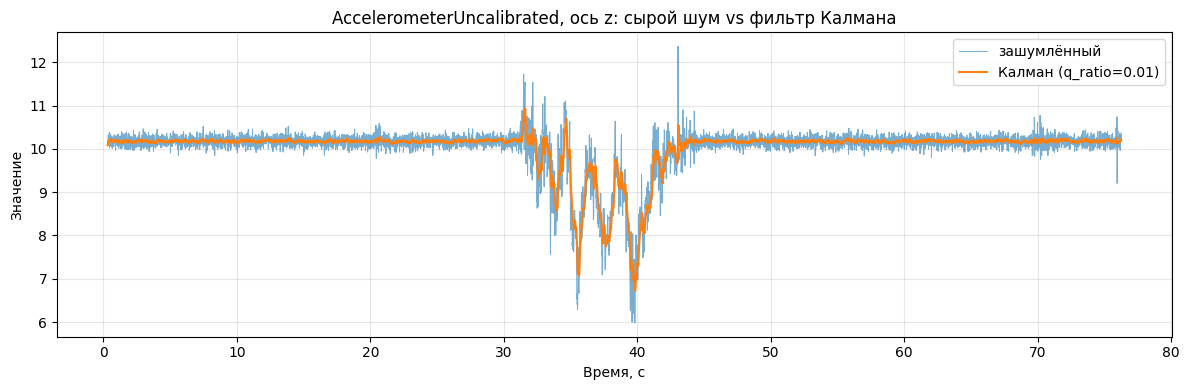

In [27]:
# ==============================================================================
# ФИЛЬТР КАЛМАНА (замена скользящего среднего)
# ==============================================================================
# Скалярный Калман на каждую ось каждого датчика. Модель — случайное
# блуждание (плавное изменение истины) + шум измерения. Параметр q_ratio
# задаёт отношение дисперсии процесса к дисперсии измерения:
#     q = q_ratio · r
# Малый q_ratio  (например, 0.001) — сильное сглаживание, но возможное
#                                   отставание при быстром движении.
# Большой q_ratio (например, 0.5)  — почти доверяем измерениям.

# Дисперсия измерения r по каждой оси оценивается по неподвижному участку.
# Используем уже рассчитанные амплитуды шума (2·СКО), делим на 2 -> получаем СКО,
# затем возводим в квадрат -> дисперсию.
def estimate_measurement_variance(std_amplitude_dict):
    """r = (амплитуда/2)^2 для каждой оси (т.к. амплитуда = 2·СКО)."""
    return {axis: (amp / 2.0) ** 2 for axis, amp in std_amplitude_dict.items()}


# ------------------------------------------------------------------------------
# 1. Ядро: скалярный Калман для 1D-сигнала (чистая функция, вход не мутируется)
# ------------------------------------------------------------------------------
def kalman_filter_1d(measurements, q, r,
                     initial_state=None,
                     initial_covariance=1.0):
    """
    Скалярный фильтр Калмана (random-walk модель).

    Параметры:
        measurements        : array-like, входной сигнал z_k
        q                   : дисперсия процесса (>0)
        r                   : дисперсия измерения (>0)
        initial_state       : x_0 (по умолчанию — первое измерение)
        initial_covariance  : P_0 (по умолчанию 1.0)

    Возвращает:
        np.ndarray отфильтрованного сигнала той же длины.
    """
    z = np.asarray(measurements, dtype=float)
    n = z.size
    if n == 0:
        return np.empty(0)

    x = float(z[0]) if initial_state is None else float(initial_state)
    p = float(initial_covariance)

    out = np.empty(n)
    for k in range(n):
        # --- Predict: x⁻ = x,  P⁻ = P + q
        x_pred = x
        p_pred = p + q

        # --- Update: K = P⁻ / (P⁻ + r)
        denom = p_pred + r
        K = p_pred / denom if denom > 0 else 0.0
        x = x_pred + K * (z[k] - x_pred)
        p = (1.0 - K) * p_pred

        out[k] = x
    return out


# ------------------------------------------------------------------------------
# 2. Обёртка над датафреймом датчика: фильтруем все три оси
# ------------------------------------------------------------------------------
def kalman_filter_sensor(df, q_ratio, r_by_axis, axes=AXES):
    """
    Прогоняет каждую ось через скалярный Калман.
    q_ratio — безразмерный коэффициент (q = q_ratio · r для соответствующей оси).

    Возвращает НОВЫЙ DataFrame (вход не мутируется).
    """
    filtered = df.copy()
    for axis in axes:
        r = r_by_axis[axis]
        q = q_ratio * r
        filtered[axis] = kalman_filter_1d(df[axis].to_numpy(), q=q, r=r)
    return filtered


# ------------------------------------------------------------------------------
# 3. Оценки дисперсии измерения по исходным (незашумлённым) датчикам
# ------------------------------------------------------------------------------
# noise_amplitudes получены в блоке генерации шумов: {axis: 2·СКО}.
r_accel = estimate_measurement_variance(noise_amplitudes["AccelerometerUncalibrated"])
r_gyro  = estimate_measurement_variance(noise_amplitudes["Gyroscope"])

print("=" * 60)
print("ДИСПЕРСИИ ИЗМЕРЕНИЯ r (по неподвижному участку)")
print("=" * 60)
print(f"AccelerometerUncalibrated: {r_accel}")
print(f"Gyroscope:                 {r_gyro}")


# ------------------------------------------------------------------------------
# 4. Демонстрация: сравнение «сырой шум / Калман» на одном канале
# ------------------------------------------------------------------------------
Q_RATIO_DEMO = 0.01  # попробуйте 0.001 / 0.01 / 0.1

demo_sensor  = "AccelerometerUncalibrated"
demo_axis    = "z"                                   # у этой оси шум 1000 Гц -> алиас ~15 Гц
demo_raw     = noisy_data[demo_sensor]
demo_r       = r_accel
demo_q       = Q_RATIO_DEMO * demo_r[demo_axis]
demo_filtered = kalman_filter_1d(demo_raw[demo_axis].to_numpy(),
                                 q=demo_q, r=demo_r[demo_axis])

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(demo_raw["seconds_elapsed"], demo_raw[demo_axis],
        label="зашумлённый",   linewidth=0.7, alpha=0.6)
ax.plot(demo_raw["seconds_elapsed"], demo_filtered,
        label=f"Калман (q_ratio={Q_RATIO_DEMO})", linewidth=1.5)
ax.set_title(f"{demo_sensor}, ось {demo_axis}: сырой шум vs фильтр Калмана")
ax.set_xlabel("Время, с")
ax.set_ylabel("Значение")
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()


# ------------------------------------------------------------------------------
# 5. Готовые функции для подачи в run_gyrovertical (без изменения алгоритма)
# ------------------------------------------------------------------------------
def make_kalman_streams(q_ratio):
    """
    Возвращает пару (accel_df, gyro_df) с фильтром Калмана по каждой оси.
    Использование:
        accel_k, gyro_k = make_kalman_streams(q_ratio=0.01)
        run_gyrovertical(accel_k, gyro_k, K=K_COEFF)
    """
    accel_k = kalman_filter_sensor(noisy_data["AccelerometerUncalibrated"],
                                   q_ratio=q_ratio, r_by_axis=r_accel)
    gyro_k  = kalman_filter_sensor(noisy_data["Gyroscope"],
                                   q_ratio=q_ratio, r_by_axis=r_gyro)
    return accel_k, gyro_k

# АЛГОРИТМ ГИРОВЕРТИКАЛИ

СИНХРОНИЗАЦИЯ ДЛЯ ГИРОВЕРТИКАЛИ
Gyroscope: clean=7706 сэмплов, noisy=7706 сэмплов
AccelerometerUncalibrated: clean=7706 сэмплов, noisy=7706 сэмплов


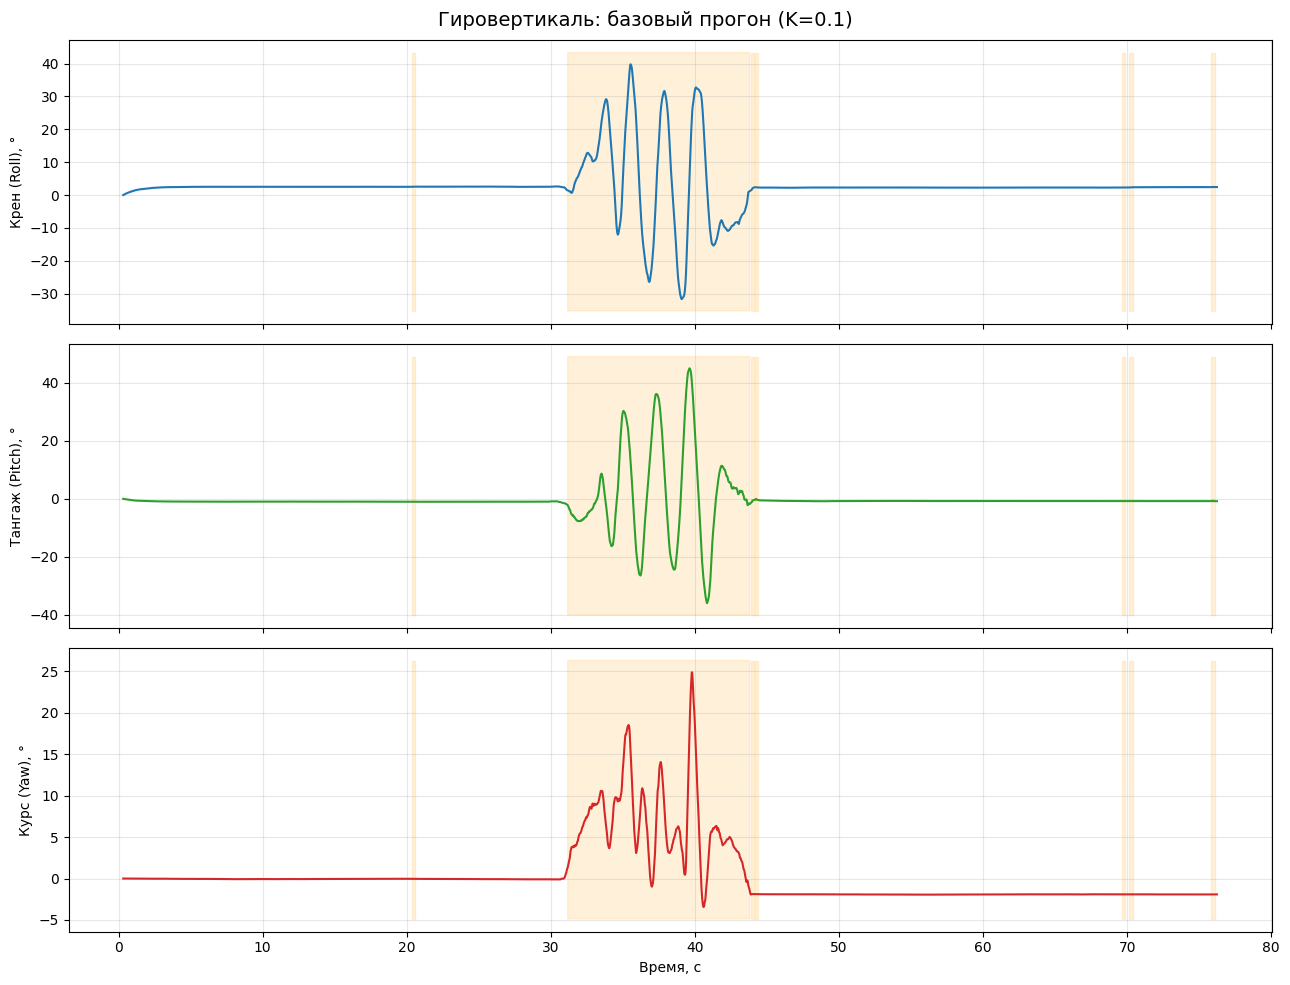

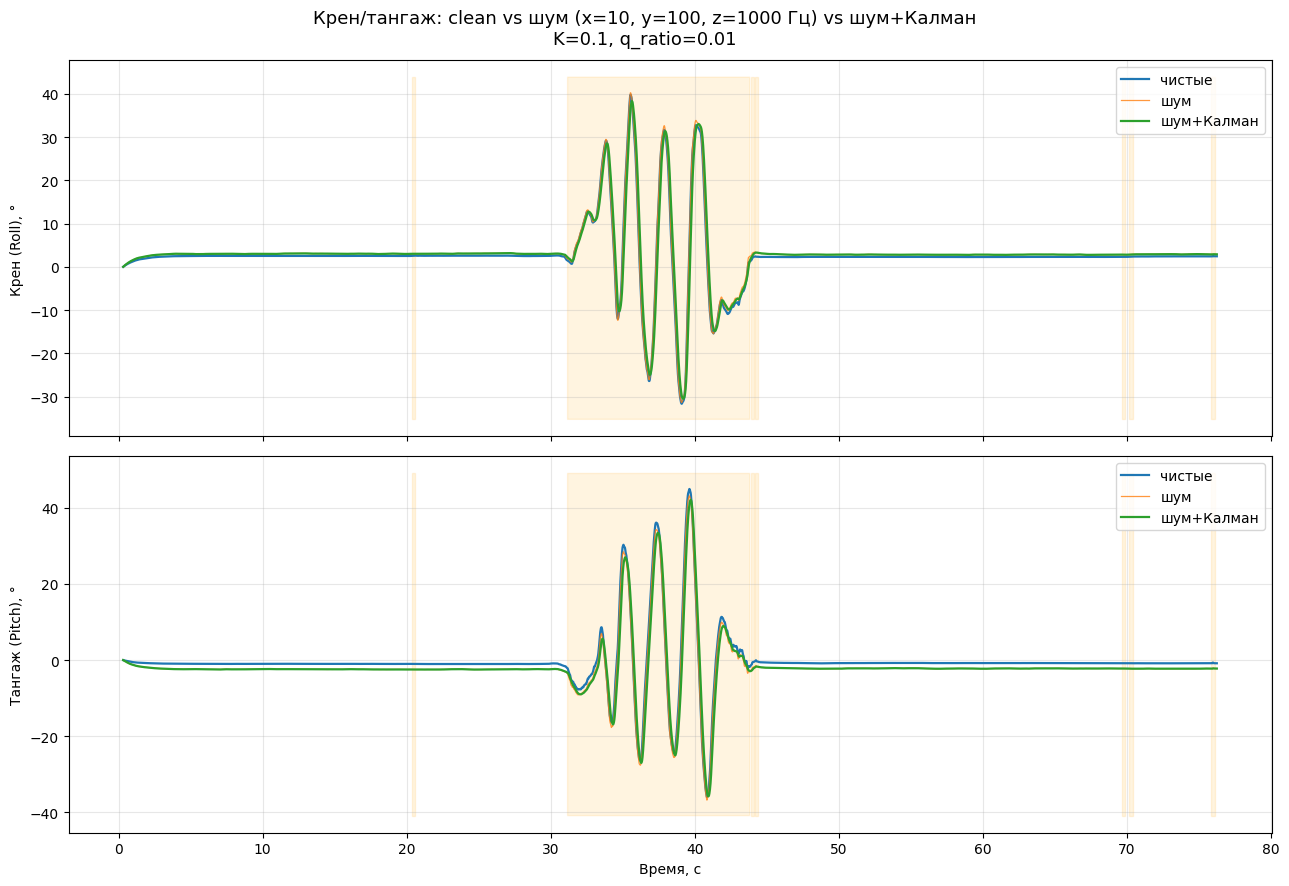

СВОДНЫЕ МЕТРИКИ (СКО на полках и дрейф, °)
Сценарий     r_std_1   p_std_1   r_std_2   p_std_2   r_drift   p_drift
----------------------------------------------------------------------
clean          0.378     0.145     0.015     0.006     0.015     0.104
noisy          0.444     0.357     0.024     0.021     0.022     0.045
kalman         0.443     0.357     0.021     0.019     0.022     0.044


In [28]:
# «Чистый» синхронизированный набор
clean_streams = {
    sensor: extract_sensor_from_synchronized(synchronized, sensor)
    for sensor in ("Gyroscope", "AccelerometerUncalibrated")
}

# Зашумлённый синхронизированный набор (тот же трек времени)
noisy_synchronized = {
    sensor: sync_sensor_to_common_time(noisy_data[sensor], common_time)
    for sensor in ("Gyroscope", "AccelerometerUncalibrated")
}

print("=" * 60)
print("СИНХРОНИЗАЦИЯ ДЛЯ ГИРОВЕРТИКАЛИ")
print("=" * 60)
for k in clean_streams:
    print(f"{k}: clean={len(clean_streams[k])} сэмплов, "
          f"noisy={len(noisy_synchronized[k])} сэмплов")

# ==============================================================================
# ВСПОМОГАТЕЛЬНЫЕ ФУНКЦИИ
# ==============================================================================
def skew_symmetric(w):
    """Создает кососимметричную матрицу из вектора угловых скоростей"""
    return np.array([
        [0,      -w[2],   w[1]],
        [w[2],    0,     -w[0]],
        [-w[1],   w[0],   0   ]
    ])

def orthonormalize(C):
    """
    Ортонормирование матрицы (метод Грама-Шмидта).
    Необходимо, чтобы матрица не 'разъезжалась' из-за численного интегрирования.
    """
    x = C[:, 0]
    y = C[:, 1]
    
    # Нормализация первого столбца
    x = x / np.linalg.norm(x)
    # Ортогонализация и нормализация второго столбца
    y = y - np.dot(x, y) * x
    y = y / np.linalg.norm(y)
    # Третий столбец - векторное произведение
    z = np.cross(x, y)
    
    return np.column_stack((x, y, z))

# ==============================================================================
# ШАГИ АЛГОРИТМА ГИРОВЕРТИКАЛИ
# ==============================================================================

def step1_transform_accel(C_prev, accel_body):
    """Шаг 1: Перевод ускорений в горизонтальную систему координат (ГСК)"""
    # n_gsk = C_{i-1} * n_body
    n_gsk = C_prev @ accel_body
    return n_gsk

def step2_correcting_vels(n_gsk, K):
    """Шаг 2: Формирование корректирующих угловых скоростей"""
    # n_gsk имеет вид [n_N, n_E, n_H] (Север, Восток, Верх/Низ)
    n_N, n_E, n_H = n_gsk
    
    # Формулы из методички (знаки зависят от принятой СК, берем как на фото)
    Omega_E = -K * n_N
    Omega_N = K * n_E
    Omega_H = 0.0
    
    # Возвращаем вектор корректирующих скоростей в ГСК
    return np.array([Omega_N, Omega_E, Omega_H])

def step3_derivative_dcm(C_prev, Omega, omega):
    """Шаг 3: Вычисление производной матрицы направляющих косинусов"""
    # A(Omega) - матрица корректирующих скоростей (в ГСК)
    # B(omega) - матрица измеренных скоростей гироскопа (в связанной СК)
    A = skew_symmetric(Omega)
    B = skew_symmetric(omega)
    
    # dC/dt = A(Omega)*C + C*B(omega)
    dC_dt = A @ C_prev + C_prev @ B
    return dC_dt

def step4_integrate_dcm(C_prev, dC_dt, dt):
    """Шаг 4: Интегрирование матрицы (метод Эйлера)"""
    C_new = C_prev + dC_dt * dt
    # Обязательно ортонормируем, чтобы матрица оставалась матрицей вращения!
    C_new = orthonormalize(C_new)
    return C_new

def step5_extract_angles(C):
    """Шаг 5: Извлечение углов крена, тангажа и курса из МНК"""
    # Предполагаем стандартный порядок Z-Y-X (Курс, Тангаж, Крен)
    # C[2,0] = -sin(Тангаж)
    pitch = np.arcsin(-C[2, 0])
    
    # Защита от Gimbal Lock (когда тангаж = 90 градусов)
    if np.abs(C[2, 0]) < 0.9999:
        roll = np.arctan2(C[2, 1], C[2, 2])
        yaw = np.arctan2(C[1, 0], C[0, 0])
    else:
        roll = np.arctan2(-C[1, 2], C[1, 1])
        yaw = 0.0
        
    # Переводим в градусы
    return np.degrees([roll, pitch, yaw])

# ==============================================================================
# ОБЩИЙ ПАЙПЛАЙН (PIPELINE)
# ==============================================================================

def run_gyrovertical(accel_df, gyro_df, K=0.5, *,
                     time_col="seconds_elapsed",
                     return_diagnostics=False):
    """
    Гировертикаль (5 шагов).

    Требует синхронизированных по времени accel_df и gyro_df.
    Если временные метки не совпадают, выдаёт предупреждение и
    использует время accel_df.

    Parameters
    ----------
    accel_df, gyro_df : DataFrame с колонками x, y, z и time_col
    K : float
        Коэффициент коррекции (диапазон 0.01..10).
    return_diagnostics : bool
        Если True, дополнительно возвращает финальную C-матрицу.

    Returns
    -------
    t : np.ndarray (n,)
    angles : np.ndarray (n, 3) — [roll, pitch, yaw] в градусах
    """
    if len(accel_df) == 0 or len(gyro_df) == 0:
        raise ValueError("run_gyrovertical: пустые входные данные")

    n = min(len(accel_df), len(gyro_df))
    axes_list = list(AXES)

    accel = accel_df[axes_list].to_numpy(dtype=float)[:n]
    gyro  = gyro_df[axes_list].to_numpy(dtype=float)[:n]
    t     = accel_df[time_col].to_numpy(dtype=float)[:n]

    # Проверка синхронности меток времени
    if time_col in gyro_df.columns:
        t_gyro = gyro_df[time_col].to_numpy(dtype=float)[:n]
        if not np.allclose(t, t_gyro, atol=1e-6):
            warnings.warn(
                "run_gyrovertical: временные метки accel и gyro не совпадают; "
                "используется время accel. Синхронизируйте входные данные."
            )

    # Инициализация
    C = np.eye(3)
    angles = np.zeros((n, 3))
    angles[0] = step5_extract_angles(C)

    # Основной цикл
    for i in range(1, n):
        dt = t[i] - t[i - 1]
        if dt <= 0:
            # Дублирующийся/обратный таймстемп — сохраняем предыдущие углы
            angles[i] = angles[i - 1]
            continue

        n_gsk = step1_transform_accel(C, accel[i])
        Omega = step2_correcting_vels(n_gsk, K)
        dC_dt = step3_derivative_dcm(C, Omega, gyro[i])
        C     = step4_integrate_dcm(C, dC_dt, dt)
        angles[i] = step5_extract_angles(C)

    if not return_diagnostics:
        return t, angles
    return t, angles, {"C_final": C}

def apply_kalman_to_synchronized(sync_noisy, q_ratio, r_accel, r_gyro,
                                 axes=AXES):
    """
    Возвращает {sensor: filtered_df} для двух датчиков, отфильтрованных
    скалярным Калманом (kalman_filter_sensor из блока Калмана).
    """
    r_by_sensor = {
        "AccelerometerUncalibrated": r_accel,
        "Gyroscope": r_gyro,
    }
    return {
        sensor: kalman_filter_sensor(
            sync_noisy[sensor],
            q_ratio=q_ratio,
            r_by_axis=r_by_sensor[sensor],
            axes=axes,
        )
        for sensor in sync_noisy
    }


# ------------------------------------------------------------------------------
# 4. Детектор движения и метрики «полка — движение — полка»
# ------------------------------------------------------------------------------
def detect_motion_mask(accel_df, window=25, threshold_factor=3.0, axes=AXES):
    """
    Бинарная маска: True там, где модуль ускорения «дышит» сильнее,
    чем на начальном неподвижном участке.

    Используется скользящее СКО модуля ускорения; порог — 3×СКО
    начального участка.
    """
    mag = np.linalg.norm(accel_df[list(axes)].to_numpy(dtype=float), axis=1)
    rolling_std = pd.Series(mag).rolling(window, center=True).std().fillna(0.0)
    baseline = float(rolling_std.iloc[:window].median()) + 1e-9
    return (rolling_std.to_numpy() > threshold_factor * baseline)


def plateau_segments(motion_mask, min_length=25):
    """
    Список (start, end) непрерывных участков «полки» (неподвижности),
    длина которых не меньше min_length.
    """
    still = (~motion_mask).astype(int)
    edges  = np.diff(np.concatenate(([0], still, [0])))
    starts = np.where(edges == 1)[0]
    ends   = np.where(edges == -1)[0]
    return [(int(s), int(e)) for s, e in zip(starts, ends)
            if (e - s) >= min_length]


def plateau_metrics(angles, motion_mask):
    """
    СКО крена/тангажа на первой и последней «полке» и дрейф
    (разность средних между последней и первой полкой).
    Возвращает None, если полок меньше двух.
    """
    segments = plateau_segments(motion_mask)
    if len(segments) < 2:
        return None

    (s0, e0), (s1, e1) = segments[0], segments[-1]
    roll, pitch = angles[:, 0], angles[:, 1]

    return {
        "roll_std_first":  float(np.std(roll[s0:e0])),
        "pitch_std_first": float(np.std(pitch[s0:e0])),
        "roll_std_last":   float(np.std(roll[s1:e1])),
        "pitch_std_last":  float(np.std(pitch[s1:e1])),
        "roll_drift":      float(np.mean(roll[s1:e1]) - np.mean(roll[s0:e0])),
        "pitch_drift":     float(np.mean(pitch[s1:e1]) - np.mean(pitch[s0:e0])),
        "first_segment":   (s0, e0),
        "last_segment":    (s1, e1),
    }

# ==============================================================================
# ЗАПУСК И ВИЗУАЛИЗАЦИЯ
# ==============================================================================

# ------------------------------------------------------------------------------
# 5. Полный пайплайн: clean / noisy / noisy+Kalman
# ------------------------------------------------------------------------------
K_COEFF = 0.1        # коэффициент коррекции (диапазон 0.01..10)
Q_RATIO = 0.01       # q_ratio для Калмана (0.001..0.1)

# Сценарий 1: чистые данные
t_clean, angles_clean = run_gyrovertical(
    clean_streams["AccelerometerUncalibrated"],
    clean_streams["Gyroscope"],
    K=K_COEFF,
)

# Сценарий 2: шум без фильтрации
t_noisy, angles_noisy = run_gyrovertical(
    noisy_synchronized["AccelerometerUncalibrated"],
    noisy_synchronized["Gyroscope"],
    K=K_COEFF,
)

# Сценарий 3: шум + Калман
noisy_kalman = apply_kalman_to_synchronized(
    noisy_synchronized, Q_RATIO, r_accel, r_gyro,
)
t_kalman, angles_kalman = run_gyrovertical(
    noisy_kalman["AccelerometerUncalibrated"],
    noisy_kalman["Gyroscope"],
    K=K_COEFF,
)

# Маска движения — строим по чистым данным (эталон)
motion_mask = detect_motion_mask(clean_streams["AccelerometerUncalibrated"])


# ------------------------------------------------------------------------------
# 6. Визуализация
# ------------------------------------------------------------------------------
# --- Рисунок 1: базовый прогон + заливка «движения» ---
fig, axes_plot = plt.subplots(3, 1, figsize=(13, 10), sharex=True)
fig.suptitle(f"Гировертикаль: базовый прогон (K={K_COEFF})", fontsize=14)

labels = [
    (0, "Крен (Roll), °",   "tab:blue"),
    (1, "Тангаж (Pitch), °", "tab:green"),
    (2, "Курс (Yaw), °",    "tab:red"),
]
for ax, (idx, label, color) in zip(axes_plot, labels):
    ax.plot(t_clean, angles_clean[:, idx], color=color, linewidth=1.5)
    ymin, ymax = ax.get_ylim()
    ax.fill_between(t_clean, ymin, ymax, where=motion_mask,
                    color="orange", alpha=0.15)
    ax.set_ylabel(label)
    ax.grid(True, alpha=0.3)

axes_plot[-1].set_xlabel("Время, с")
plt.tight_layout()
plt.show()

# --- Рисунок 2: сравнение сценариев (крен и тангаж) ---
fig, axes_plot = plt.subplots(2, 1, figsize=(13, 9), sharex=True)
fig.suptitle(
    "Крен/тангаж: clean vs шум (x=10, y=100, z=1000 Гц) vs шум+Калман\n"
    f"K={K_COEFF}, q_ratio={Q_RATIO}",
    fontsize=13,
)

for ax, (idx, label) in zip(
    axes_plot,
    [(0, "Крен (Roll), °"), (1, "Тангаж (Pitch), °")],
):
    ax.plot(t_clean,  angles_clean[:, idx],  label="чистые",     linewidth=1.6)
    ax.plot(t_noisy,  angles_noisy[:, idx],  label="шум",        linewidth=0.9, alpha=0.8)
    ax.plot(t_kalman, angles_kalman[:, idx], label="шум+Калман", linewidth=1.6)
    ymin, ymax = ax.get_ylim()
    ax.fill_between(t_clean, ymin, ymax, where=motion_mask,
                    color="orange", alpha=0.12)
    ax.set_ylabel(label)
    ax.grid(True, alpha=0.3)
    ax.legend(loc="upper right")

axes_plot[-1].set_xlabel("Время, с")
plt.tight_layout()
plt.show()


# ------------------------------------------------------------------------------
# 7. Сводная таблица метрик
# ------------------------------------------------------------------------------
results = {
    "clean":  plateau_metrics(angles_clean,  motion_mask),
    "noisy":  plateau_metrics(angles_noisy,  motion_mask),
    "kalman": plateau_metrics(angles_kalman, motion_mask),
}

print("=" * 80)
print("СВОДНЫЕ МЕТРИКИ (СКО на полках и дрейф, °)")
print("=" * 80)
header = (f"{'Сценарий':<10} {'r_std_1':>9} {'p_std_1':>9} "
          f"{'r_std_2':>9} {'p_std_2':>9} {'r_drift':>9} {'p_drift':>9}")
print(header)
print("-" * len(header))
for name, m in results.items():
    if m is None:
        print(f"{name:<10} — не удалось выделить обе полки")
        continue
    print(f"{name:<10} "
          f"{m['roll_std_first']:>9.3f} "
          f"{m['pitch_std_first']:>9.3f} "
          f"{m['roll_std_last']:>9.3f} "
          f"{m['pitch_std_last']:>9.3f} "
          f"{m['roll_drift']:>9.3f} "
          f"{m['pitch_drift']:>9.3f}")


подбоор k

In [29]:
K_values = [0.01, 0.05, 0.1, 0.5, 1.0, 5.0]

k_results = {}

print("Запуск гировертикали для разных K...")

for K in K_values:
    t_k, angles_k = run_gyrovertical(
        noisy_synchronized["AccelerometerUncalibrated"],
        noisy_synchronized["Gyroscope"],
        K=K
    )

    k_results[K] = (t_k, angles_k)
    print(f"K={K} - вычислено")

Запуск гировертикали для разных K...
K=0.01 - вычислено
K=0.05 - вычислено
K=0.1 - вычислено
K=0.5 - вычислено
K=1.0 - вычислено
K=5.0 - вычислено


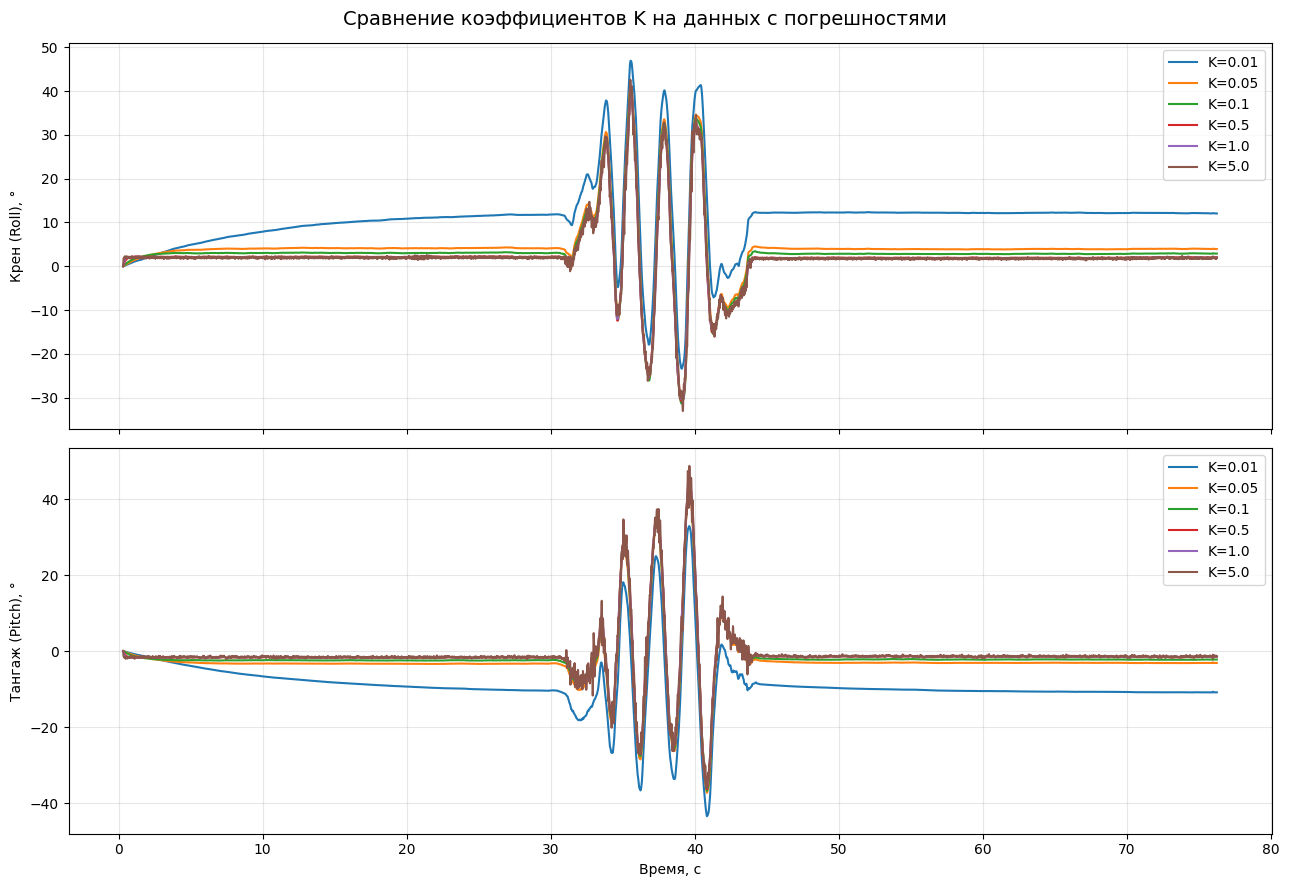

In [30]:
fig, axes_plot = plt.subplots(2, 1, figsize=(13, 9), sharex=True)

fig.suptitle(
    "Сравнение коэффициентов K на данных с погрешностями",
    fontsize=14
)

for K in K_values:
    t_k, angles_k = k_results[K]

    axes_plot[0].plot(t_k, angles_k[:, 0], label=f"K={K}")
    axes_plot[1].plot(t_k, angles_k[:, 1], label=f"K={K}")

axes_plot[0].set_ylabel("Крен (Roll), °")
axes_plot[1].set_ylabel("Тангаж (Pitch), °")
axes_plot[1].set_xlabel("Время, с")

for ax in axes_plot:
    ax.grid(True, alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

In [31]:
print("=" * 75)
print("СРАВНЕНИЕ K ПО СТАБИЛЬНОСТИ НА НЕПОДВИЖНЫХ УЧАСТКАХ")
print("=" * 75)

print(f"{'K':<8} {'r_std_1':>10} {'p_std_1':>10} "
      f"{'r_std_2':>10} {'p_std_2':>10} "
      f"{'r_drift':>10} {'p_drift':>10}")

print("-" * 75)

for K in K_values:
    t_k, angles_k = k_results[K]
    m = plateau_metrics(angles_k, motion_mask)

    if m is None:
        print(f"{K:<8} — не удалось выделить полки")
        continue

    print(
        f"{K:<8} "
        f"{m['roll_std_first']:>10.3f} "
        f"{m['pitch_std_first']:>10.3f} "
        f"{m['roll_std_last']:>10.3f} "
        f"{m['pitch_std_last']:>10.3f} "
        f"{m['roll_drift']:>10.3f} "
        f"{m['pitch_drift']:>10.3f}"
    )

СРАВНЕНИЕ K ПО СТАБИЛЬНОСТИ НА НЕПОДВИЖНЫХ УЧАСТКАХ
K           r_std_1    p_std_1    r_std_2    p_std_2    r_drift    p_drift
---------------------------------------------------------------------------
0.01          3.040      2.638      0.039      0.013      4.877     -4.762
0.05          0.808      0.661      0.022      0.014      0.256     -0.153
0.1           0.444      0.357      0.024      0.021      0.022      0.045
0.5           0.151      0.126      0.038      0.056     -0.089      0.142
1.0           0.111      0.110      0.051      0.080     -0.098      0.150
5.0           0.123      0.154      0.118      0.157     -0.104      0.154


# ДОПОЛНИТЕЛЬНЫЙ ЭКСПЕРИМЕНТ: фильтр Калмана с состоянием (угол, смещение гироскопа)

Ячейки выше не меняются. Здесь Калман объединяет два датчика (sensor fusion):

- **прогноз**: угол по гироскопу, $\theta_k=\theta_{k-1}+(u_k-b_{k-1})\Delta t$;
- **измерение**: угол по акселерометру, $z_k$.

Состояние $x=(\theta, b)^T$. Отдельный фильтр для крена и для тангажа. Курс по акселерометру исправить нельзя.

In [ ]:
def kalman_angle_step(x, P, u, z, dt, Q, R):
    """Один шаг: x = (угол, смещение), u - скорость по гироскопу, z - угол по акселерометру."""
    F = np.array([[1.0, -dt],
                  [0.0, 1.0]])          # матрица перехода
    B = np.array([dt, 0.0])             # матрица управления
    H = np.array([[1.0, 0.0]])          # матрица измерения: видим только угол

    # Прогноз
    x = F @ x + B * u
    P = F @ P @ F.T + Q * dt            # Q задана на секунду

    # Коррекция
    S = (H @ P @ H.T).item() + R
    K = (P @ H.T).ravel() / S           # коэффициент Калмана
    x = x + K * (z - x[0])
    P = (np.eye(2) - np.outer(K, H)) @ P
    return x, P


def run_kalman_angles(accel_df, gyro_df, q_angle=0.001, q_bias=0.0001, r_angle=0.03):
    """Крен и тангаж (градусы) и оценки смещения (рад/с)."""
    t = accel_df["seconds_elapsed"].to_numpy()
    ax, ay, az = accel_df[["x", "y", "z"]].to_numpy().T
    wx, wy, wz = gyro_df[["x", "y", "z"]].to_numpy().T

    # Измерение: углы по направлению силы тяжести (рад)
    z_roll = np.arctan2(ay, az)
    z_pitch = np.arctan2(-ax, np.hypot(ay, az))

    Q = np.diag([q_angle, q_bias])
    x_r, x_p = np.array([z_roll[0], 0.0]), np.array([z_pitch[0], 0.0])
    P_r, P_p = np.eye(2) * 0.01, np.eye(2) * 0.01

    angles = np.zeros((len(t), 2))
    bias = np.zeros((len(t), 2))
    angles[0] = x_r[0], x_p[0]

    for k in range(1, len(t)):
        dt = t[k] - t[k - 1]
        roll, pitch = x_r[0], x_p[0]
        # Скорости гироскопа (в осях телефона) -> скорости изменения крена и тангажа
        u_roll = wx[k] + np.tan(pitch) * (np.sin(roll) * wy[k] + np.cos(roll) * wz[k])
        u_pitch = np.cos(roll) * wy[k] - np.sin(roll) * wz[k]

        x_r, P_r = kalman_angle_step(x_r, P_r, u_roll, z_roll[k], dt, Q, r_angle)
        x_p, P_p = kalman_angle_step(x_p, P_p, u_pitch, z_pitch[k], dt, Q, r_angle)

        angles[k] = x_r[0], x_p[0]
        bias[k] = x_r[1], x_p[1]

    return np.degrees(angles), bias

In [ ]:
angles_fusion, bias_fusion = run_kalman_angles(
    noisy_synchronized["AccelerometerUncalibrated"],
    noisy_synchronized["Gyroscope"],
)

# Эталон - гировертикаль на чистых данных. Первые 5 с пропускаем (она устанавливается из нуля).
settled = t_clean > t_clean[0] + 5.0
masks = {"покой": settled & ~motion_mask, "движение": settled & motion_mask}
variants = {
    "гировертикаль, шум": angles_noisy[:, :2],
    "гировертикаль, шум+сглаживание": angles_kalman[:, :2],
    "Калман (угол, смещение)": angles_fusion,
}

print("СКО ошибки относительно эталона, градусы")
print(f"{'вариант':<34}{'участок':<10}{'крен':>8}{'тангаж':>8}")
for name, ang in variants.items():
    for part, m in masks.items():
        err = np.sqrt(np.mean((ang[m] - angles_clean[m, :2]) ** 2, axis=0))
        print(f"{name:<34}{part:<10}{err[0]:8.3f}{err[1]:8.3f}")

fig, axs = plt.subplots(3, 1, figsize=(13, 11), sharex=True)
for i, label in enumerate(["Крен, °", "Тангаж, °"]):
    axs[i].plot(t_clean, angles_clean[:, i], label="эталон", linewidth=2)
    axs[i].plot(t_clean, angles_noisy[:, i], label="гировертикаль, шум")
    axs[i].plot(t_clean, angles_fusion[:, i], label="Калман (угол, смещение)")
    axs[i].set_ylabel(label)

axs[2].plot(t_clean, bias_fusion[:, 0], label="оценка b, крен")
axs[2].plot(t_clean, bias_fusion[:, 1], label="оценка b, тангаж")
axs[2].axhline(0.02, linestyle="--", color="tab:blue", label="добавленное по x: 0.02")
axs[2].axhline(-0.015, linestyle="--", color="tab:orange", label="добавленное по y: -0.015")
axs[2].set_ylabel("Смещение, рад/с")
axs[2].set_xlabel("Время, с")
for a in axs:
    a.grid(alpha=0.3)
    a.legend(loc="upper right")
plt.tight_layout()
plt.show()

In [ ]:
# Таблица и выводы по фактическим числам этого запуска
table = pd.DataFrame([
    {"вариант": name, "участок": part,
     **dict(zip(["крен, °", "тангаж, °"],
                np.sqrt(np.mean((ang[m] - angles_clean[m, :2]) ** 2, axis=0))))}
    for name, ang in variants.items() for part, m in masks.items()
])
display(table.round(3))

print("ВЫВОДЫ: гировертикаль с шумом -> Калман (угол, смещение), СКО ошибки")
for part, m in masks.items():
    for i, angle in enumerate(["крен", "тангаж"]):
        old = np.sqrt(np.mean((angles_noisy[m, i] - angles_clean[m, i]) ** 2))
        new = np.sqrt(np.mean((angles_fusion[m, i] - angles_clean[m, i]) ** 2))
        verdict = "лучше" if new < old else "хуже"
        print(f"  {part}, {angle}: {old:.3f}° -> {new:.3f}° ({verdict})")

rest_bias = bias_fusion[masks["покой"]].mean(axis=0)
print(f"Оценка смещения в покое: крен {rest_bias[0]:.4f}, тангаж {rest_bias[1]:.4f} рад/с")
print("Добавляли по осям гироскопа: x = 0.0200, y = -0.0150 рад/с")